# Classification with Artificial Neural Networks

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## The IRIS dataset

In the following we start using a [dataset](https://archive.ics.uci.edu/dataset/53/iris) (from UCI Machine Learning repository) called IRIS, which contains 3 classes of iris plants (*setosa*, *versicolor*, *virginica*) with 4 features (*sepal length*, *sepal width*, *petal length*, *petal width*).

In [4]:
from sklearn.datasets import load_iris
iris = load_iris()

In [5]:
print(iris.feature_names)
print(iris.target_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


## Model declaration

The type of prediction model and the working criteria for the model induction algorithm are declared using scikit-learn. In this case, we use a Multi-layer Perceptron (MLP) classifier. The parametrization of this first classifier is arbitrary and will result in subpar performance.

In [6]:
from sklearn.neural_network import MLPClassifier
clf_ANN = MLPClassifier(solver='adam', alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=1, max_iter=2000)

## Training and test sets

We split the dataset in a training set (to be used to fit the model) and a test set (to be used to evaluate the quality of the fitted model). In this case, we keep only 10 examples for testing selected randomly from the original dataset (using numpy).

In [7]:
np.random.seed(0)

# Generate a random permutation of the indices of examples that will be later used
# for the training and the test set
indices = np.random.permutation(len(iris.data))

# We now decide to keep the last 10 indices for test set, the remaining for the training set
indices_training=indices[:-10]
indices_test=indices[-10:]

iris_X_train = iris.data[indices_training] # keep for training all the matrix elements with the exception of the last 10
iris_y_train = iris.target[indices_training]
iris_X_test  = iris.data[indices_test] # keep the last 10 elements for test set
iris_y_test  = iris.target[indices_test]

In [8]:
# fit the model to the training data
clf_ANN = clf_ANN.fit(iris_X_train, iris_y_train)

Scikit-learn allows to access the network's training set score and loss after the training phase.

In [9]:
print("Training set score: " + str(clf_ANN.score(iris_X_train, iris_y_train)))
print("Training set loss: " + str(clf_ANN.loss_))

Training set score: 0.6714285714285714
Training set loss: 0.5559834895588641


Monitoriamo la loss per adam

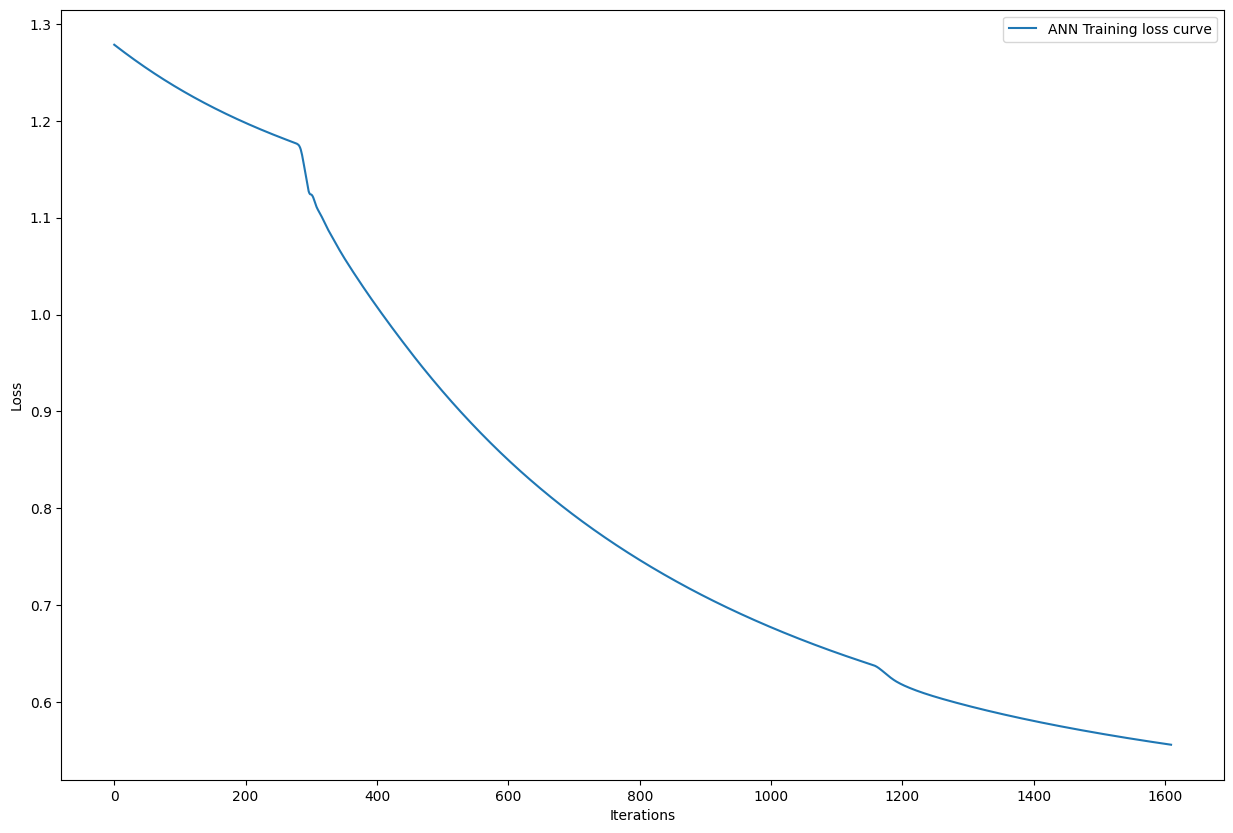

In [10]:
# The learning curve is plotted using Matplotlib
fig, axis = plt.subplots(1, figsize=(15, 10))
axis.set_xlabel("Iterations")
axis.set_ylabel("Loss")
axis.plot(clf_ANN.loss_curve_, label="ANN Training loss curve")
axis.legend()

The training loss curve can be plotted to visualize how Loss evolves during training. Beware that this curve is not gathered by all optimizers (Adam does, LBFGS doesn't).

**Adam ** is a popular and efficient ML optimizer that uses the first and second moments of the gradients to adaptively adjust the learning rate for each parameter during training. It combines *Momentum* (accelerates convergence with a moving average of past gradients) and *RMSProp* (uses the decaying moving average of squared gradients) to smooth out oscillations and prevent the vanishing or exploding gradient problems.

In [11]:
clf_ANN_sdg = MLPClassifier(solver='sgd', alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=1, max_iter=2000)
clf_ANN_sdg = clf_ANN_sdg.fit(iris_X_train, iris_y_train)

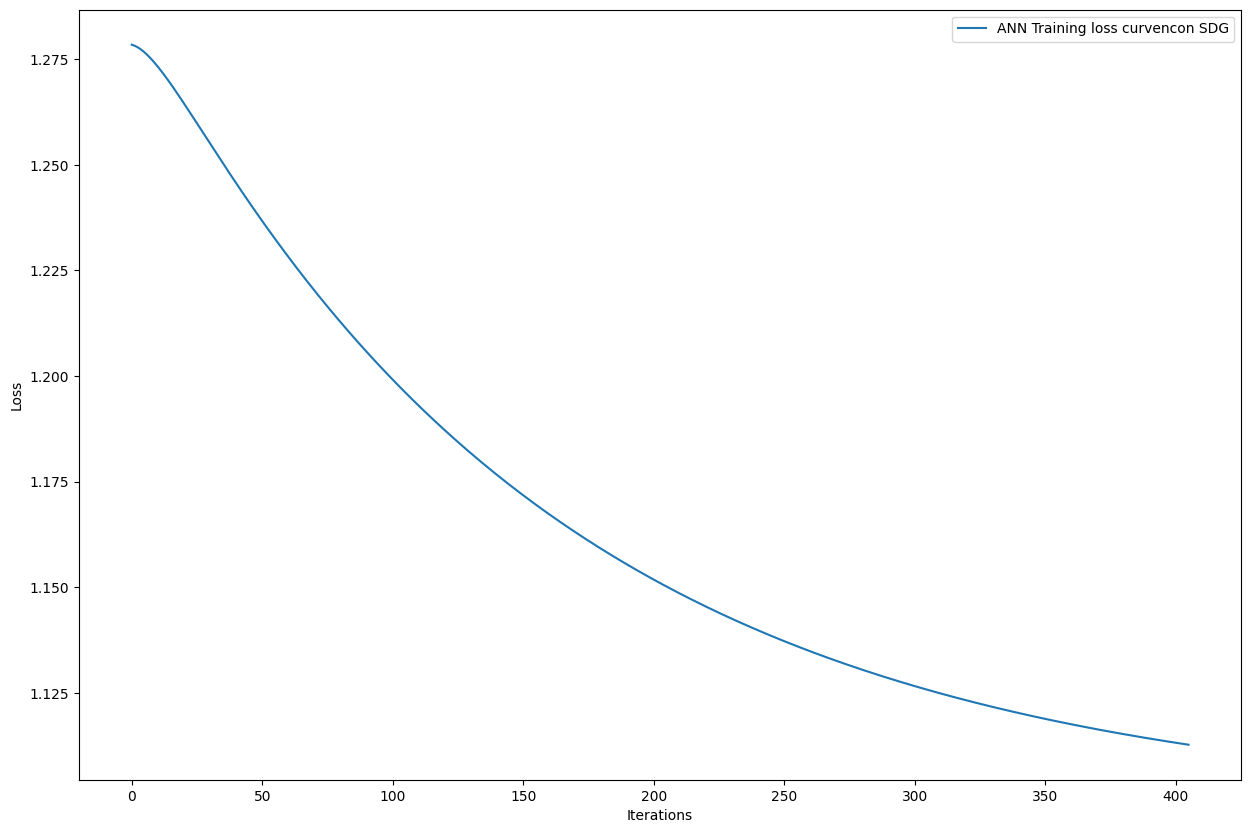

In [12]:
# The learning curve is plotted using Matplotlib
fig, axis = plt.subplots(1, figsize=(15, 10))
axis.set_xlabel("Iterations")
axis.set_ylabel("Loss")
axis.plot(clf_ANN_sdg.loss_curve_, label="ANN Training loss curvencon SDG")
axis.legend()

Once the model has been trained, it can be used to predict the class of the flowers in the test set.

In [13]:
predicted_y_test = clf_ANN.predict(iris_X_test)

print(iris.target_names)

# print the predictions (class numbers associated to classes names in target names)
print("\nPredictions:")
print(predicted_y_test)
print("True classes:")
print(iris_y_test)

['setosa' 'versicolor' 'virginica']

Predictions:
[2 2 2 0 0 0 2 2 2 0]
True classes:
[1 1 1 0 0 0 2 1 2 0]


Pandas is used to display the test data with corresponding predicted labels.

In [14]:
results_data = []

for i in range(len(iris_y_test)):
    feature_values = [iris_X_test[i][j] for j in range(len(iris.feature_names))]

    results_data.append({
        'Instance': indices_test[i],
        iris.feature_names[0]: feature_values[0],
        iris.feature_names[1]: feature_values[1],
        iris.feature_names[2]: feature_values[2],
        iris.feature_names[3]: feature_values[3],
        'Predicted': iris.target_names[predicted_y_test[i]],
        'True Class': iris.target_names[iris_y_test[i]],
        'Correct': 'Yes' if predicted_y_test[i] == iris_y_test[i] else 'No'
    })

results_df = pd.DataFrame(results_data)
print(results_df.to_string(index=False, float_format='%.1f'))

 Instance  sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm) Predicted True Class Correct
       88                5.6               3.0                4.1               1.3 virginica versicolor      No
       70                5.9               3.2                4.8               1.8 virginica versicolor      No
       87                6.3               2.3                4.4               1.3 virginica versicolor      No
       36                5.5               3.5                1.3               0.2    setosa     setosa     Yes
       21                5.1               3.7                1.5               0.4    setosa     setosa     Yes
        9                4.9               3.1                1.5               0.1    setosa     setosa     Yes
      103                6.3               2.9                5.6               1.8 virginica  virginica     Yes
       67                5.8               2.7                4.1               1.0 virginica ve

## Performance metrics

Scikit-learn provides several built-in functions to evaluate the quality of the predictions, in this case we use accuracy and F1-score.

In [15]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score

In [16]:
# print some metrics results
acc_scoreANN = accuracy_score(iris_y_test, predicted_y_test)
print("Accuracy score ANN: "+ str(acc_scoreANN))
f1=f1_score(iris_y_test, predicted_y_test, average='macro')
print("F1 score ANN: "+ str(f1))

Accuracy score ANN: 0.6
F1 score ANN: 0.5


## Cross Validation

Scikit-learn provides several built-in functions to perform cross-validation. In this case we use a $5$-fold cross-validation, and we compute the accuracy and F1-score for each fold.

In [17]:
from sklearn.model_selection import cross_val_score # will be used to separate training and test

In [18]:
iris = load_iris()
clf_ANN = MLPClassifier(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=1)

In [19]:
scoresANN = cross_val_score(clf_ANN, iris.data, iris.target, cv=5) # score will be the accuracy
print(scoresANN)
f1_scoresANN = cross_val_score(clf_ANN, iris.data, iris.target, cv=5, scoring='f1_macro')
print(f1_scoresANN)

[0.33333333 0.33333333 0.33333333 0.33333333 0.33333333]
[0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]


Scikit-learn provides built-in facilities to visualize learning curves, by also employing CV on training set of increasing size, allowing to visualize overfitting/underfitting phenomena.

In [20]:
from sklearn.model_selection import LearningCurveDisplay
from sklearn.utils import shuffle

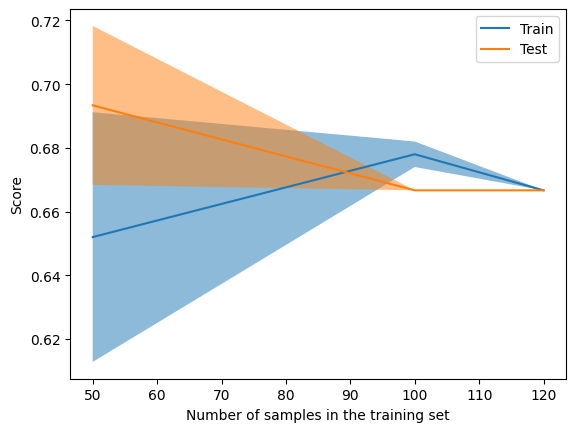

In [21]:
iris_x, iris_y = load_iris(return_X_y=True)
iris_x, iris_y = shuffle(iris_x, iris_y, random_state=0)
clf_ANN = MLPClassifier(solver='adam', alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=1, max_iter=2000)
LearningCurveDisplay.from_estimator(clf_ANN, iris_x, iris_y, train_sizes=[50, 100, 120], cv=5)

P.S. certain optimizers (like Adam) raise several convergence warnings if the maximum number of iterations is not sufficient to reach convergence. This can be visually problematic especially when trying to search for best hyperparameters (try to run the above cell with `max_iter=400`). In this case, it is possible to disable the warnings as follows:

```python
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
```

# Your work: what you have to do

Modify the given Jupyter notebook on ANN on Iris data and perform the following tasks:

1. build and show the confusion matrix obtained by cross validation, where the errors are on the test sets.
2. build the ROC curve (or coverage curve in coverage space) and plot it for the ANN: you have to build three curves, one for each class, considered in turn as the positive class.
3. get an artificial inflation of the Virginica class in the training set by a given factor: 10 (weigh more the class virginica which is difficult to discriminate with versicolor). Learn the ANN in this condition. In this case we have more examples in the dataset!

**Note:** Be careful in the random sampling when you divide the dataset into training- and test-set: no examples of the training-set should go in the test- set.

4. learn the ANN but try to avoid overfitting (by improving the error on the test set). You can do tuning of the hyper-parameters using the function [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

Consider the following hyperparameters:

- hidden_layer_sizes
- activation = {‘identity’, ‘logistic’, ‘tanh’, ‘relu’}
- solver = {‘lbfgs’, ‘sgd’, ‘adam’}
- alpha (L2 regularization term)
- batch_size (size of the mini-batch)
- learning_rate = {‘constant’, ‘invscaling’, ‘adaptive’}
- early_stopping: bool
- warm_start: bool
- max_iter

Decide yourself the suitable possible values for each of them.

5. build the ROC curves of best models (obtained after hyperparameter tuning) for both DT and ANN for each of the three classes (with *one-vs-rest* methodology). Compare the two models.

=== TASK 1: CONFUSION MATRIX ===
Confusion Matrix:
[[50  0  0]
 [ 0  0 50]
 [ 0  0 50]]


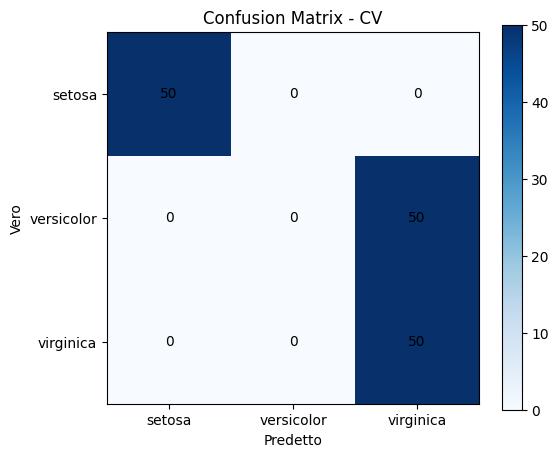

In [28]:
# TASK 1: Confusion Matrix con Cross-Validation
print("=== TASK 1: CONFUSION MATRIX ===")

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

iris = load_iris()
clf_ANN = MLPClassifier(solver='adam', alpha=1e-5, hidden_layer_sizes=(5, 2), 
                        random_state=1, max_iter=2000)

y_pred_cv = cross_val_predict(clf_ANN, iris.data, iris.target, cv=5)
cm = confusion_matrix(iris.target, y_pred_cv)

print("Confusion Matrix:")
print(cm)

# Visualizzazione
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
plt.colorbar(im)

ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(iris.target_names)
ax.set_yticklabels(iris.target_names)

for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center")

ax.set_xlabel('Predetto')
ax.set_ylabel('Vero')
ax.set_title('Confusion Matrix - CV')
plt.show()


=== TASK 2: CURVE ROC ===


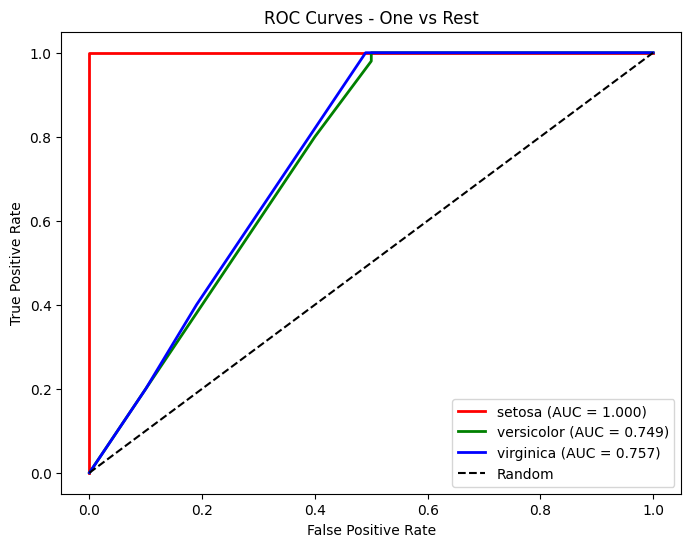

In [ ]:
# TASK 2: Curve ROC
print("\n=== TASK 2: CURVE ROC ===")

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_bin = label_binarize(iris.target, classes=[0, 1, 2])
y_proba_cv = cross_val_predict(clf_ANN, iris.data, iris.target, cv=5, method='predict_proba')

plt.figure(figsize=(8, 6))
colors = ['red', 'green', 'blue']

# Per ogni classe di Iris calcoliamo e tracciamo la curva ROC
for i, (class_name, color) in enumerate(zip(iris.target_names, colors)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba_cv[:, i])
    #y_bin è la matrice binarizzata delle etichette vere
    #y_proba_cv sono le probabilità previste per la classe i-esima
    #fpr e tpr sono i valori di false positive rate e true positive rate immagazzinati come array numpy
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, color=color, linewidth=2,
             label=f'{class_name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - One vs Rest')
plt.legend()
plt.show()

In [ ]:
# TASK 3: Inflazione Virginica
print("\n=== TASK 3: INFLAZIONE VIRGINICA ===")

from sklearn.model_selection import train_test_split

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Prima inflazione:", np.bincount(y_train))

# Trova e duplica Virginica 9 volte
virginica_indices = np.where(y_train == 2)[0]
for i in range(9):
    X_train = np.vstack([X_train, X_train[virginica_indices]])
    y_train = np.hstack([y_train, y_train[virginica_indices]])

print("Dopo inflazione:", np.bincount(y_train))

# Modello normale
clf_normal = MLPClassifier(solver='adam', alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=1, max_iter=2000)
X_train_orig = X_train[:105]  # Solo primi 105 esempi (originali)
y_train_orig = y_train[:105]
clf_normal.fit(X_train_orig, y_train_orig)
acc_normal = clf_normal.score(X_test, y_test)

# Modello inflazionato
clf_inflated = MLPClassifier(solver='adam', alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=1, max_iter=2000)
clf_inflated.fit(X_train, y_train)
acc_inflated = clf_inflated.score(X_test, y_test)

print(f"Accuracy normale: {acc_normal:.3f}")
print(f"Accuracy inflazionata: {acc_inflated:.3f}")


=== TASK 3: INFLAZIONE VIRGINICA ===
Prima inflazione: [31 37 37]
Dopo inflazione: [ 31  37 370]
Accuracy normale: 0.711
Accuracy inflazionata: 0.978


Per ottimizzare gli iperparametri utilizziamo il gridsearch

In [36]:
# TASK 4: GridSearchCV per ottimizzazione iperparametri
print("\n=== TASK 4: GRIDSEARCHCV ===")

from sklearn.model_selection import GridSearchCV
import warnings
from sklearn.exceptions import ConvergenceWarning

# Disabilita i warning di convergenza
warnings.filterwarnings("ignore", category=ConvergenceWarning)

iris = load_iris()
X, y = iris.data, iris.target

# Split train/test (importante: prima del GridSearch!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Griglia SEMPLIFICATA per evitare warning
param_grid = {
    'hidden_layer_sizes': [(10,), (20,), (10, 5)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.001, 0.01],
    'max_iter': [2000]  # Fisso per evitare problemi di convergenza
}

# Crea il modello base con solver fisso
mlp = MLPClassifier(solver='adam', random_state=1)

# GridSearchCV
grid_search = GridSearchCV(
    mlp, 
    param_grid, 
    cv=3,                    # Ridotto a 3 per velocità
    scoring='accuracy',
    n_jobs=1,               # Un solo job per evitare conflitti
    verbose=0               # Nessun output durante la ricerca
)

print("Inizio GridSearchCV...")
grid_search.fit(X_train, y_train)

# Migliori parametri trovati
print("Migliori parametri:", grid_search.best_params_)
print("Miglior score CV:", grid_search.best_score_)

# Valuta sul test set
best_model = grid_search.best_estimator_
test_accuracy = best_model.score(X_test, y_test)
print(f"Accuracy test set: {test_accuracy:.3f}")


=== TASK 4: GRIDSEARCHCV ===
Inizio GridSearchCV...
Migliori parametri: {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (20,), 'max_iter': 2000}
Miglior score CV: 0.9619047619047619
Accuracy test set: 1.000



=== TASK 5: CONFRONTO ANN vs DECISION TREE ===
Ottimizzazione Decision Tree...
Migliori parametri DT: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 2}
Miglior score CV DT: 0.9333333333333332
Accuracy finale ANN: 1.000
Accuracy finale DT: 1.000
Calcolo curve ROC con cross-validation...


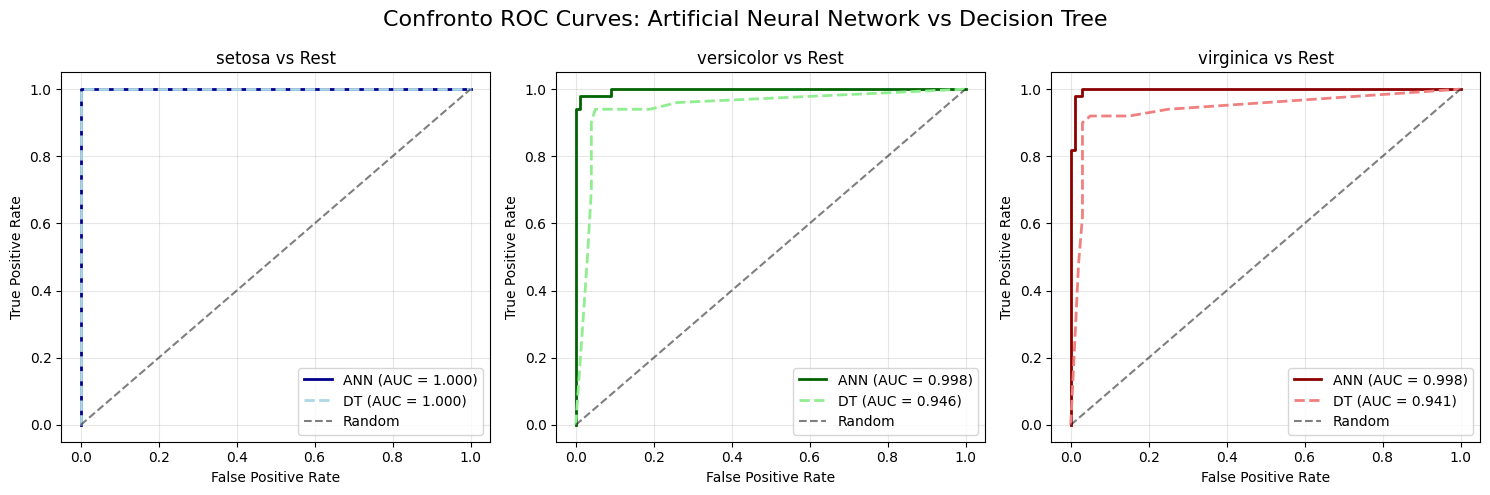


=== CONFRONTO DETTAGLIATO ===
ANN - Migliori parametri: {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (20,), 'max_iter': 2000}
DT  - Migliori parametri: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 2}

Accuracy Cross-Validation:
ANN: 0.962
DT:  0.933

Accuracy Test Set:
ANN: 1.000
DT:  1.000

AUC per classe:
setosa       - ANN: 1.000, DT: 1.000
versicolor   - ANN: 0.998, DT: 0.946
virginica    - ANN: 0.998, DT: 0.941

=== CONCLUSIONE ===
🤝 ANN e Decision Tree hanno performance simili!


In [38]:
# TASK 5: Confronto ROC ANN vs Decision Tree
print("\n=== TASK 5: CONFRONTO ANN vs DECISION TREE ===")

from sklearn.tree import DecisionTreeClassifier

# Ottimizza anche Decision Tree con GridSearchCV
print("Ottimizzazione Decision Tree...")
dt_param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

dt = DecisionTreeClassifier(random_state=1)
dt_grid_search = GridSearchCV(dt, dt_param_grid, cv=3, scoring='accuracy', n_jobs=1, verbose=0)
dt_grid_search.fit(X_train, y_train)

print("Migliori parametri DT:", dt_grid_search.best_params_)
print("Miglior score CV DT:", dt_grid_search.best_score_)

# Modelli ottimizzati
best_ann = grid_search.best_estimator_
best_dt = dt_grid_search.best_estimator_

# Accuracy finale sui test set
ann_final_acc = best_ann.score(X_test, y_test)
dt_final_acc = best_dt.score(X_test, y_test)

print(f"Accuracy finale ANN: {ann_final_acc:.3f}")
print(f"Accuracy finale DT: {dt_final_acc:.3f}")

# Per le curve ROC, utilizziamo cross-validation su tutto il dataset
iris = load_iris()
X, y = iris.data, iris.target

# Predizioni probabilistiche con cross-validation
print("Calcolo curve ROC con cross-validation...")
y_bin = label_binarize(y, classes=[0, 1, 2])

# Probabilità ANN con cross-validation
ann_proba = cross_val_predict(best_ann, X, y, cv=5, method='predict_proba')

# Probabilità Decision Tree con cross-validation  
dt_proba = cross_val_predict(best_dt, X, y, cv=5, method='predict_proba')

# Plot confronto ROC per ogni classe
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors_ann = ['darkblue', 'darkgreen', 'darkred']
colors_dt = ['lightblue', 'lightgreen', 'lightcoral']

for i, class_name in enumerate(iris.target_names):
    ax = axes[i]
    
    # ROC per ANN
    fpr_ann, tpr_ann, _ = roc_curve(y_bin[:, i], ann_proba[:, i])
    auc_ann = auc(fpr_ann, tpr_ann)
    
    # ROC per Decision Tree
    fpr_dt, tpr_dt, _ = roc_curve(y_bin[:, i], dt_proba[:, i])
    auc_dt = auc(fpr_dt, tpr_dt)
    
    # Plot entrambe le curve
    ax.plot(fpr_ann, tpr_ann, color=colors_ann[i], linewidth=2, 
            label=f'ANN (AUC = {auc_ann:.3f})')
    ax.plot(fpr_dt, tpr_dt, color=colors_dt[i], linewidth=2, linestyle='--',
            label=f'DT (AUC = {auc_dt:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
    
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{class_name} vs Rest')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Confronto ROC Curves: Artificial Neural Network vs Decision Tree', fontsize=16)
plt.tight_layout()
plt.show()

# Confronto dettagliato delle performance
print("\n=== CONFRONTO DETTAGLIATO ===")
print(f"ANN - Migliori parametri: {grid_search.best_params_}")
print(f"DT  - Migliori parametri: {dt_grid_search.best_params_}")
print(f"\nAccuracy Cross-Validation:")
print(f"ANN: {grid_search.best_score_:.3f}")
print(f"DT:  {dt_grid_search.best_score_:.3f}")
print(f"\nAccuracy Test Set:")
print(f"ANN: {ann_final_acc:.3f}")
print(f"DT:  {dt_final_acc:.3f}")

# Confronto AUC per classe
print(f"\nAUC per classe:")
for i, class_name in enumerate(iris.target_names):
    fpr_ann, tpr_ann, _ = roc_curve(y_bin[:, i], ann_proba[:, i])
    auc_ann = auc(fpr_ann, tpr_ann)
    
    fpr_dt, tpr_dt, _ = roc_curve(y_bin[:, i], dt_proba[:, i])
    auc_dt = auc(fpr_dt, tpr_dt)
    
    print(f"{class_name:12} - ANN: {auc_ann:.3f}, DT: {auc_dt:.3f}")

# Conclusione
print(f"\n=== CONCLUSIONE ===")
if ann_final_acc > dt_final_acc:
    print("🏆 ANN performa meglio in termini di accuracy!")
elif dt_final_acc > ann_final_acc:
    print("🏆 Decision Tree performa meglio in termini di accuracy!")
else:
    print("🤝 ANN e Decision Tree hanno performance simili!")